# Calibrated E. coli fluorescence abundances

## Problem
Recover thirteen relative label-brightness images from one measured confocal spectral ROI. Broad overlapping emission bands make independent color-channel thresholding insufficient. The ROI is the complete author-distributed 30×30 demonstration, extracted upstream from a larger microscope acquisition. No independent ground truth abundance exists. The archived original output is a **method reference**, not truth.


## Benchmark acceptance revision 2

The actively reconstructed SLPRU arrays and NLS/SNLS/SLNLS comparisons below preserve historical implementations. NCC/NRMSE against upstream are reproduction diagnostics, not current acceptance criteria. Current acceptance uses the public global convex KL/nuclear/group objective and retained physical/observation constraints. This differs from historical local nonconvex reweighting; no equivalence is claimed. More accurate feasible objective minimizers are accepted. Digital-intensity likelihoods remain approximate for the processed export.


In [1]:
import os,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'data/raw_data.npz').exists(): root=root.parent
os.chdir(root)
from src.preprocessing import load_data,FLUOROPHORES
from src.solvers import reconstruct
from src.physics_model import relative_observation_error
from src.visualization import acquisition_figure,abundance_figure,residual_figure,agreement
from evaluation.judge import evaluate
image,spectra=load_data()
with np.load('notebooks/reference_outputs/upstream_methods.npz',allow_pickle=False) as z:
    upstream={k:z[k][0] for k in z.files}
print('Measured observations:',image.shape,image.dtype,'; calibration:',spectra.shape)


Measured observations: (30, 30, 24) uint8 ; calibration: (24, 13)


## Data
The observations are an 8-bit processed microscope export, with retained Zeiss metadata: 63×/1.40 oil objective, lateral pitch99.521491860627815nm and24 spectral channels spanning approximately492–725nm. Separately stained E. coli controls provide13 fixed spectral response columns. The data are **author_real_processed** rather than absolute photon counts. The plot shows all controls and their pairwise spectral similarities; no target-derived calibration is used.

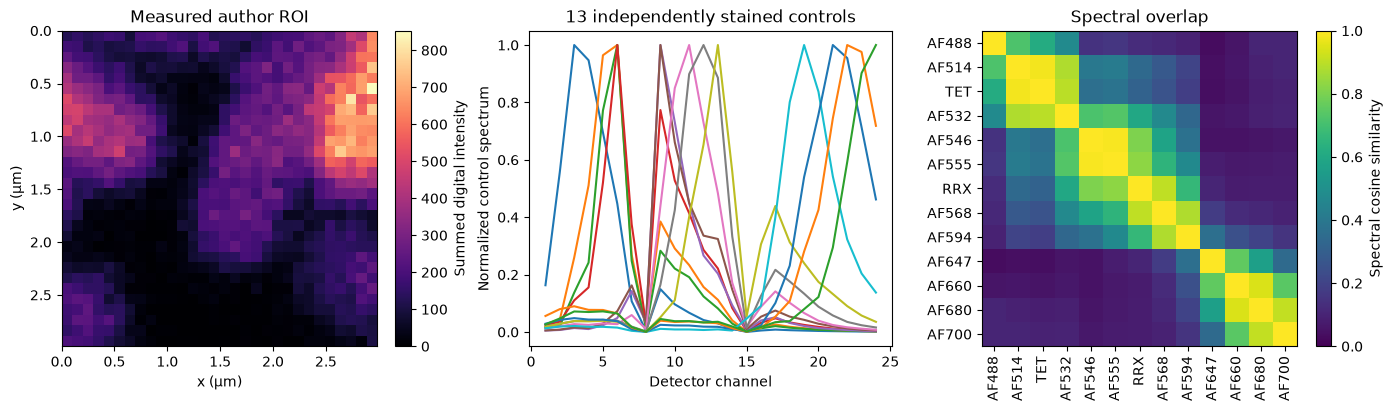

Calibration rank: 13 condition number: 306.2246207312709


In [2]:
fig=acquisition_figure(image,spectra)
plt.show()
print('Calibration rank:',np.linalg.matrix_rank(spectra),'condition number:',np.linalg.cond(spectra))


## Physics
For each spatial pixel, expected recorded intensity is M a, where M is the24×13 nonnegative control-spectrum matrix and a contains13 nonnegative brightness coefficients. The detector sums spectrally overlapping emission. Brightness coefficients are not fractions and do not sum to one.

A Poisson-like fidelity sums predicted intensity minus measured intensity times log prediction. This reflects signal-dependent fluctuations but is only approximate after8-bit processing. Reconstruction is reported relative to its global maximum; residual calculations therefore restore exactly one nonnegative detector gain, alpha=dot(prediction,observation)/dot(prediction,prediction). No spatial warp, label permutation or per-pixel scaling is allowed. The one-pixel border is zero because a full3×3 neighborhood is unavailable.

## Method
Actively solve every nonzero interior neighborhood with the cleaned local ADMM implementation. Each3×3 window is RMS-normalized. Split variables represent spectral prediction, reweighted low rank, reweighted row-group sparsity and positivity. The spectral update solves a quadratic positive root; the rank update thresholds singular values; the group update shrinks entire fluorophore rows. Scaled dual residuals adapt the penalty every10 iterations, up to1000 steps.

The original implementation recomputes inverse singular-value and inverse group-norm weights, so this is a reweighted implementation rather than the simple convex norm formulation alone. Both selected penalties are0.1. We preserve the original numerical conventions and explicitly report iteration-cap behavior.

The paper's four comparison families are retained: NLS, sparse NLS, sparse+low-rank NLS, and sparse+low-rank Poisson regression. These are computed now from measured observations. The notebook does not regenerate the paper's synthetic performance study or claim reproduction of its unavailable full plaque stack; the bound demonstration is the author's E. coli ROI.

In [3]:
fresh={};diagnostics={};runtime={}
for method in ('NLS','SNLS','SLNLS','SLPRU'):
    start=time.perf_counter()
    fresh[method],diagnostics[method]=reconstruct(image,spectra,method=method)
    runtime[method]=time.perf_counter()-start
    ncc,nrmse=agreement(fresh[method],upstream[method])
    print(f'{method:6s} fresh seconds={runtime[method]:.2f}, upstream NCC={ncc:.12f}, NRMSE={nrmse:.3e}')
    np.testing.assert_allclose(fresh[method],upstream[method],rtol=2e-5,atol=2e-6)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh['SLPRU'][None])
np.savez_compressed('notebooks/reference_outputs/cleaned_methods.npz',**{k:v[None] for k,v in fresh.items()})
report,exit_code=evaluate('output/reconstruction.npz')
assert exit_code==0,report
print(json.dumps(report,indent=2))


NLS    fresh seconds=10.74, upstream NCC=1.000000000000, NRMSE=2.630e-15


SNLS   fresh seconds=13.59, upstream NCC=1.000000000000, NRMSE=6.510e-15


SLNLS  fresh seconds=14.20, upstream NCC=1.000000000000, NRMSE=1.930e-15


SLPRU  fresh seconds=59.69, upstream NCC=1.000000000000, NRMSE=2.306e-15
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 2.305678883718358e-15,
    "observation_relative_error": 0.3346126088610371
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "observation_relative_error": {
      "comparison": "<=",
      "boundary": 0.3680738697471408
    }
  },
  "errors": []
}


## Results
All thirteen fluorophore images are plotted with the same0–1 color scale. Each row is a freshly reconstructed method with its own single global normalization. Images represent relative brightness; a brighter label is not automatically a larger molecular concentration.

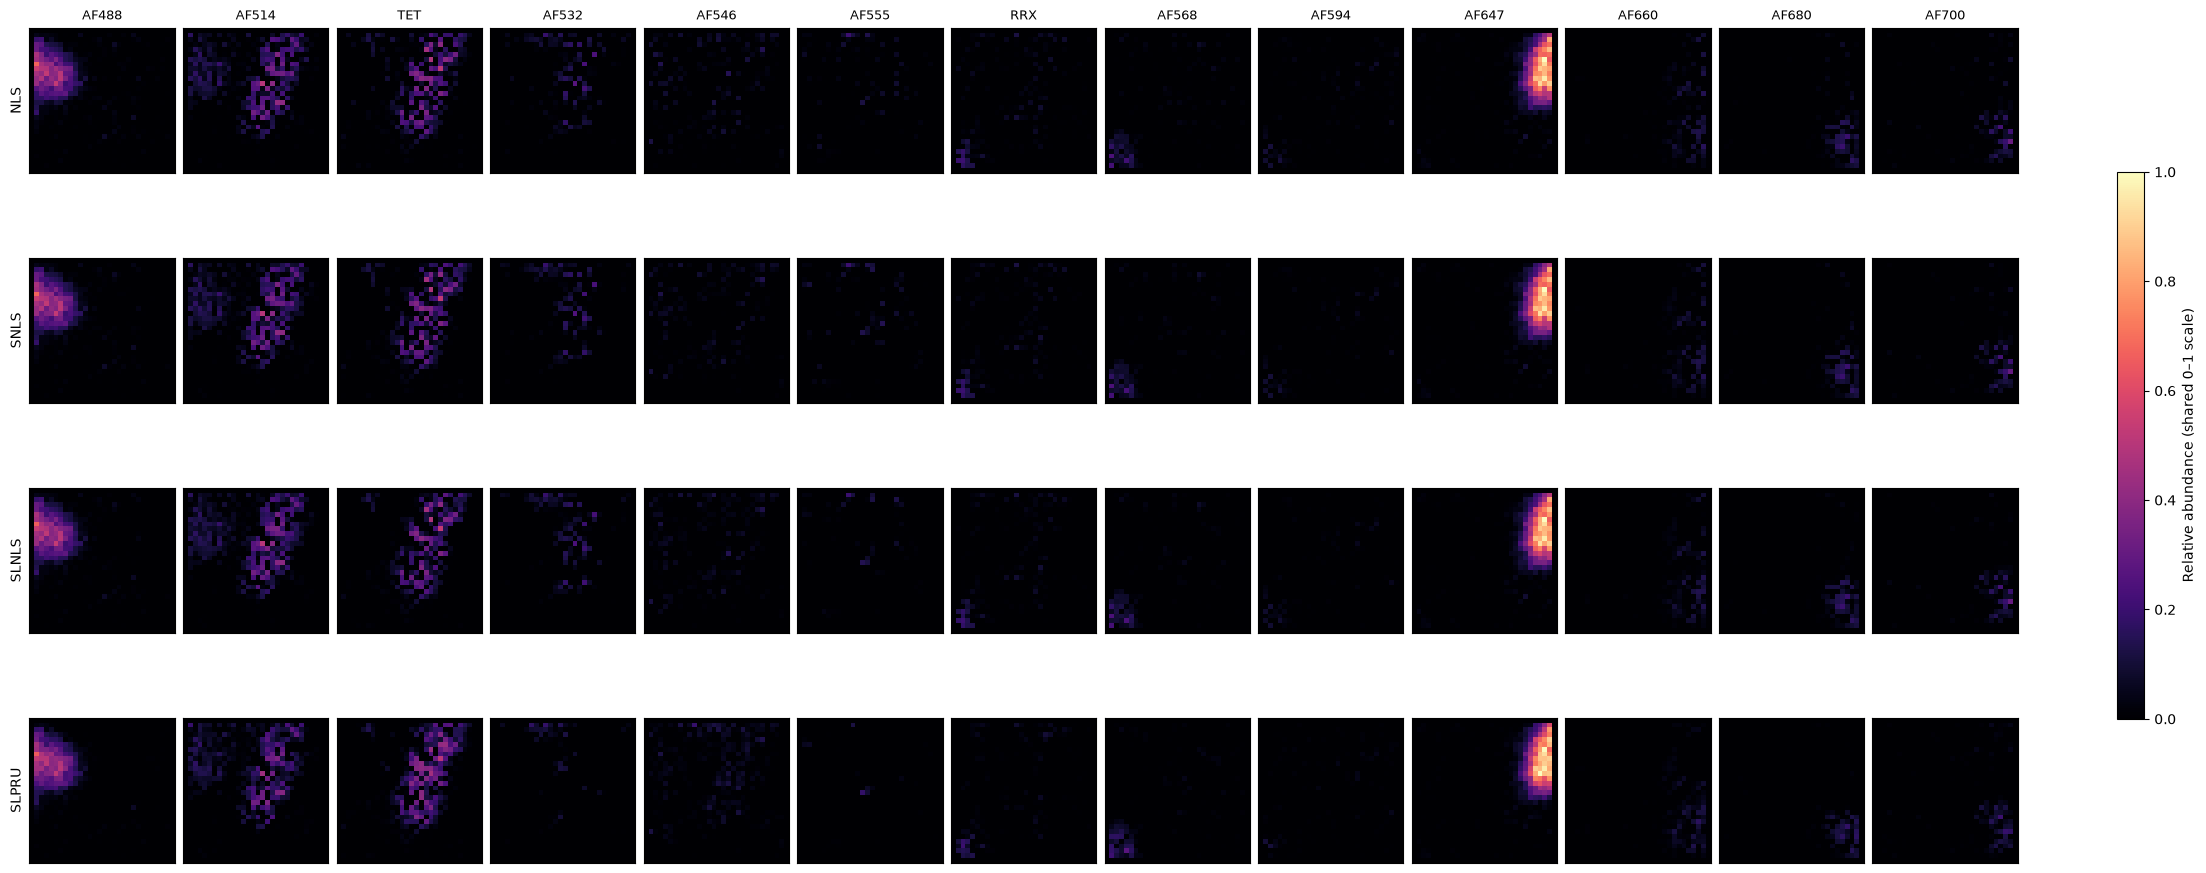

In [4]:
fig=abundance_figure(fresh)
plt.show()


### Observation consistency and sparse solutions
Residual maps use the same one-gain convention for every method. The lower plots show the same central pixel. Low residual alone rewards fitting noise and spectral cross-talk; regularized solutions intentionally trade residual for structure. There is no independent abundance truth against which to declare a winning biological accuracy.

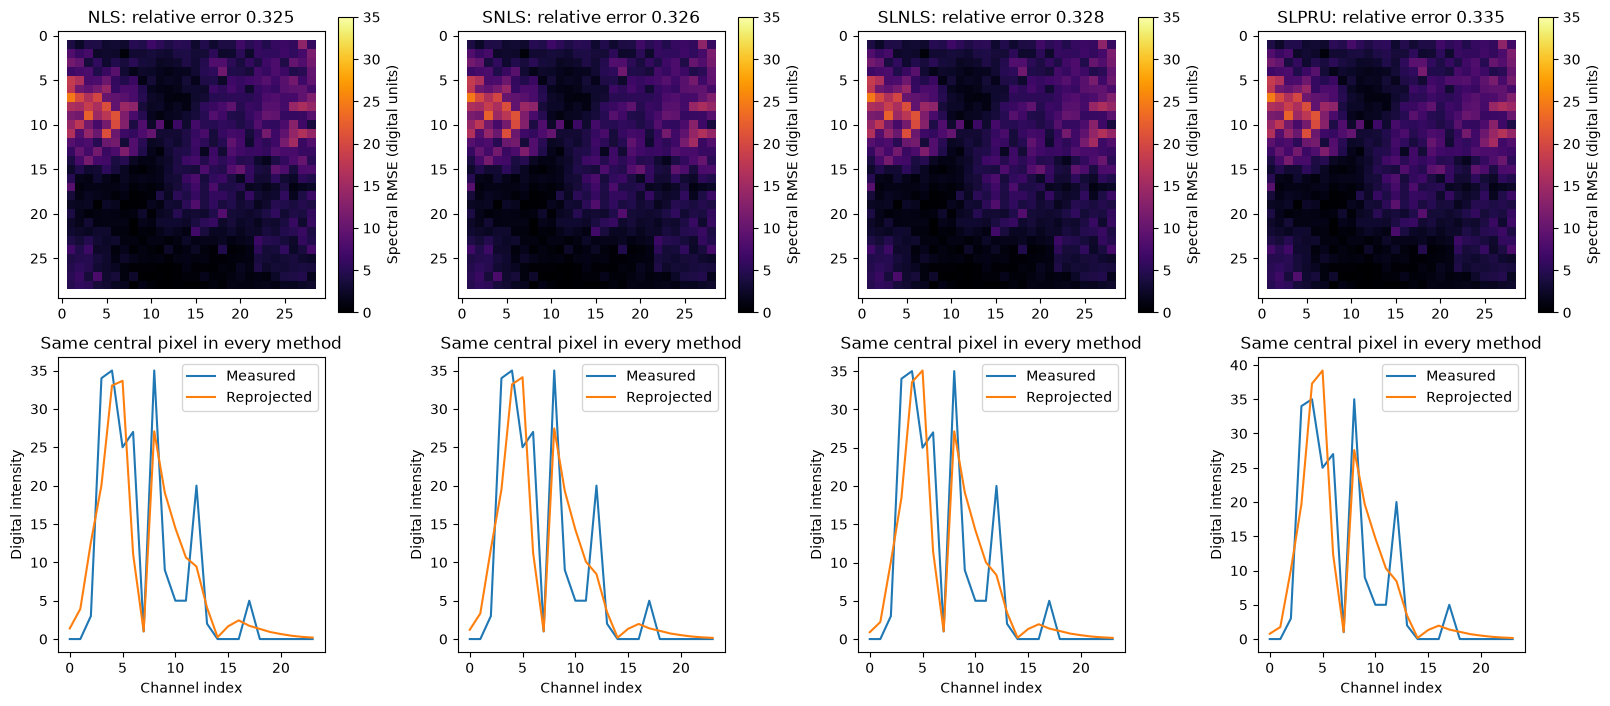

method | relative observation error | gain | mean labels>0.01 | cap fraction | upstream NCC | NRMSE | seconds
['NLS', 0.32548265955358946, 174.11922984305622, np.float64(2.318877551020408), np.float64(0.0), 1.0000000000000002, 2.629615427359772e-15, 10.73800469993148]
['SNLS', 0.32622008350386267, 174.61320047819675, np.float64(2.2232142857142856), np.float64(0.0012755102040816326), 1.0, 6.509770830820551e-15, 13.588682999950834]
['SLNLS', 0.32755198403916935, 174.28438208314805, np.float64(2.1466836734693877), np.float64(0.008928571428571428), 1.0, 1.929951354060996e-15, 14.198007700033486]
['SLPRU', 0.3346126088610371, 173.6073034047275, np.float64(2.079081632653061), np.float64(0.5599489795918368), 1.0000000000000002, 2.305678883718358e-15, 59.68669610004872]


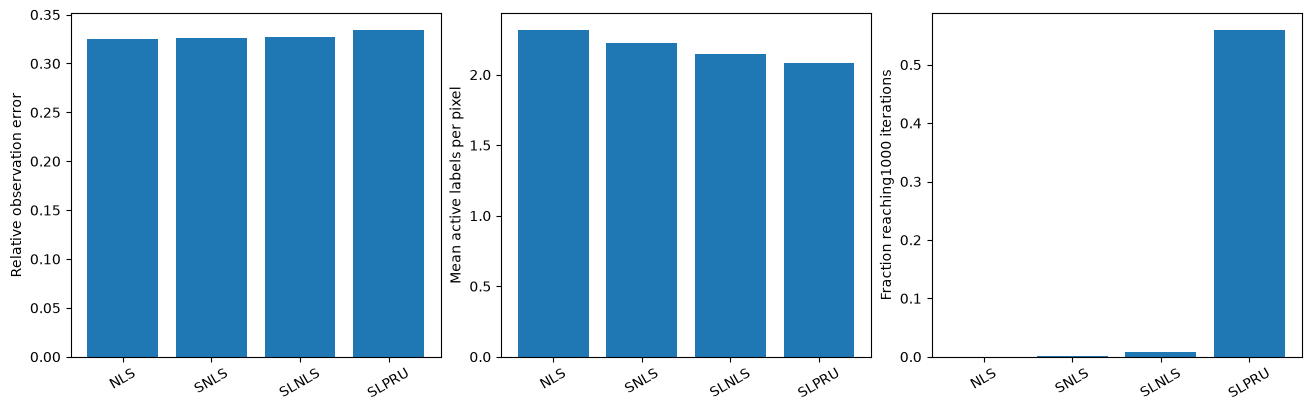

In [5]:
fig=residual_figure(image,spectra,fresh)
plt.show()
rows=[]
for name,a in fresh.items():
    ncc,nrmse=agreement(a,upstream[name]);res,gain=relative_observation_error(a,image,spectra)
    active=np.mean(np.sum(a[1:-1,1:-1]>.01,axis=-1))
    capped=np.mean(diagnostics[name]['iterations'][1:-1,1:-1]==1000)
    rows.append([name,res,gain,active,capped,ncc,nrmse,runtime[name]])
print('method | relative observation error | gain | mean labels>0.01 | cap fraction | upstream NCC | NRMSE | seconds')
for row in rows:print(row)
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
names=[q[0] for q in rows]
for ax,k,label in zip(axes,[1,3,4],['Relative observation error','Mean active labels per pixel','Fraction reaching1000 iterations']):
    ax.bar(names,[q[k] for q in rows]);ax.set_ylabel(label);ax.tick_params(axis='x',rotation=30)
plt.show()


### Ablation: remove the fluorophore-group penalty
Hold the count-aware fidelity and low-rank penalty fixed, and set only the group penalty to zero. Both outputs below are fresh complete reconstructions, not replacements by archived images. This tests how the prior changes spectral allocation under the same measured data.

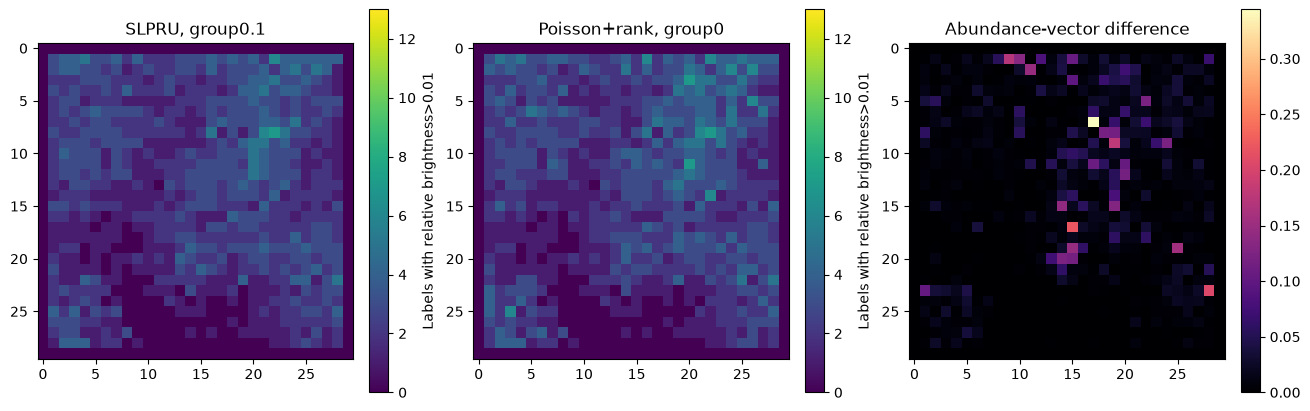

Ablation seconds: 56.476160799968056
Full / no-group residual: 0.3346126088610371 0.3332501544930834


1191

In [6]:
start=time.perf_counter()
no_group,no_group_diag=reconstruct(image,spectra,lambda_group=0.)
ablation_seconds=time.perf_counter()-start
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,a,label in zip(axes[:2],[fresh['SLPRU'],no_group],['SLPRU, group0.1','Poisson+rank, group0']):
    im=ax.imshow(np.sum(a>.01,axis=-1),vmin=0,vmax=13,cmap='viridis');ax.set_title(label);fig.colorbar(im,ax=ax,label='Labels with relative brightness>0.01')
im=axes[2].imshow(np.linalg.norm(fresh['SLPRU']-no_group,axis=-1),cmap='magma');axes[2].set_title('Abundance-vector difference');fig.colorbar(im,ax=axes[2])
plt.show()
print('Ablation seconds:',ablation_seconds)
print('Full / no-group residual:',relative_observation_error(fresh['SLPRU'],image,spectra)[0],relative_observation_error(no_group,image,spectra)[0])
metrics={'runtime_seconds':runtime,'ablation_seconds':ablation_seconds,'table_columns':['method','observation_error','gain','active_labels','cap_fraction','upstream_ncc','upstream_nrmse','seconds'],'rows':rows}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(metrics,indent=2,allow_nan=False),encoding='utf-8')


## Conclusion
The fresh local reconstruction agrees with independently executed upstream SLPRU and preserves the paper's four comparison families. Calibrated spectral overlap explains why regularization changes fluorophore allocation. The observed residual and iteration-cap fractions describe the actual limitations; they are not evidence of exact Poisson statistics or fully converged optimization.

No true abundance field is available. Passing numerical reference agreement establishes method reproduction, not biological accuracy. The task binds a small processed author ROI, and results should not be generalized to the full microscope field, raw photon counts or absolute molecular concentrations without additional data and calibration.